In [1]:
# numba's LLVM crashes when compiling for my Snapdragon X (oryon-1) CPU, so target a generic ARMv8 CPU instead
import os
os.environ["NUMBA_CPU_NAME"] = "generic"

import matplotlib.pyplot as plt
from reducers.pca import PCA
from reducers.umap import UMAP
from reducers.utils import load_mnist, to_matrix, plot_embedding

/app/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load data
X_train, y_train = to_matrix(load_mnist(train=True))
X_test, y_test = to_matrix(load_mnist(train=False))

In [3]:
reducers = {"PCA": PCA(2), "UMAP": UMAP(2, random_state=0)}
embeddings = {name: r.fit(X_train).transform(X_test) for name, r in reducers.items()}

/app/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


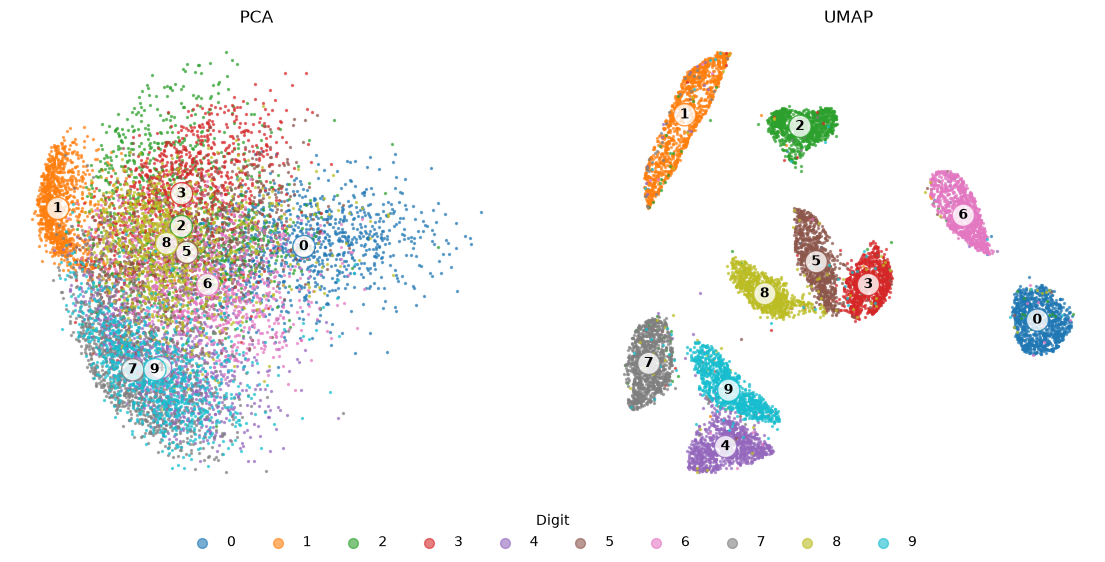

In [4]:
fig, axes = plt.subplots(1, len(embeddings), figsize=(14, 6))
for ax, (name, Z) in zip(axes, embeddings.items()):
    plot_embedding(Z, y_test, ax=ax, title=name)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=10, title="Digit", markerscale=5, frameon=False)
fig.savefig("figures/mnist_pca_vs_umap.png", dpi=150, bbox_inches="tight")
plt.show()